# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_: 
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how Euler's method and RK4 work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Maribao, Jake Agustin B.
- _Student No._: 2023-08777
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="lorenz_butterfly.png" alt="Lorenz butterfly" width=45%> <img src="vdp_phase.png" alt="Van der Pol phase space" width=45%>

_Figure 1. Left: the Lorenz strange attractor, z against x, for σ = 10, ρ = 28 and β = 8/3 from t = 0 to 50, starting at (x, y, z) = (0, 1, 0). The red crosses mark the two unstable fixed points C± = (±8.49, ±8.49, 27) that the two lobes wind around. Right: phase space (dx/dt against x) of the van der Pol oscillator with ω = 1 and μ = 1, 2 and 4 from t = 0 to 20, starting at x = 1, dx/dt = 0 (black dot). Every curve settles onto a limit cycle, and a larger μ gives a more distorted cycle with a longer period. Both figures use RK4 (h = 0.005 for Lorenz and h = 0.002 for van der Pol)._

### Report discussion

**Explain the dynamics in the figures.** The butterfly is the Lorenz system at ρ = 28. The trajectory circles one of two unstable fixed points C± = (±8.49, ±8.49, 27), then jumps to the other lobe after an irregular number of turns and never repeats. This is deterministic chaos: two runs that start 10^-8 apart differ by more than 1 after t ≈ 33, so the path is unpredictable even though the equations have no randomness. At ρ = 14, the same start simply spirals into a fixed point. In the van der Pol plot, every μ ends on the same kind of closed loop, a limit cycle reaching x ≈ ±2. The term μ(1 - x²)dx/dt feeds energy in when |x| < 1 and removes it when |x| > 1. A larger μ distorts the cycle into slow drifts and fast jumps and lengthens the period from 6.66 to 7.63 to 10.20.

**How do Euler's method and RK4 work?** Both methods march the solution forward in steps of size h using the slope f(t, y) given by the differential equation. Euler's method takes the slope at the start of each step and moves along that straight line, y(n+1) = y(n) + h f(t(n), y(n)). As a first-order Taylor step, its error per step is O(h²) and its global error is O(h). RK4 samples the slope four times per step, once at the start, twice at the midpoint and once at the end, each using the previous sample to estimate where the solution is. It then moves by a weighted average of these slopes with weights 1, 2, 2 and 1 over 6, which cancels the error terms up to h⁴ and gives a global error of O(h⁴). A system, or a second-order equation rewritten as two first-order ones, is handled the same way with y as a vector.

**Advantages and disadvantages of Euler vs RK4.** Euler's method is simple to code and needs only one evaluation of f per step, but its O(h) error forces very small steps. On the harmonic oscillator up to t = 50 with h = 0.005, Euler was off by 0.13 and its energy grew by 28%, because every step spirals slightly outward. RK4 with the same h was off by only 2.5×10^-10. It costs four evaluations per step, yet Euler with h/4, at the same total cost, was still off by 0.03. The disadvantages of RK4 are the extra work per step and the longer code, and it also does not conserve energy exactly, so it can drift over very long runs. Neither method can follow a chaotic path forever. For the Lorenz system, halving h changes the solution after t ≈ 29, so at late times only the shape of the attractor is reliable.

### Other comments
- `euler()` and `rk4()` are copied from Section 3 into the top of Section 2, because Section 3 comes after the exercises and a top-to-bottom run would otherwise fail. They also stop after n - 1 steps, so no step is wasted past the last time.
- Exercise 2(b): the harmonic period is 6.2832 = 2π for both x(0) = 1 and 2. Exercise 2(c): the anharmonic periods are 14.83, 7.42 and 3.71 for x(0) = 0.5, 1 and 2, matching the exact T = Γ(1/4)²/(√π ω x(0)), so doubling the amplitude halves the period.
- Halving h for the van der Pol oscillator changes the solution by at most 8×10^-8, so h = 0.002 is small enough for a smooth and accurate plot.
- Reflection: the Lorenz step-size test surprised me. Even RK4 loses the exact trajectory after t ≈ 29, which shows that chaos limits prediction no matter how good the integrator is.


---
## Section 2: Code

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### ODE solvers
`euler()` and `rk4()` from Section 3, written for systems of equations and placed here so that the notebook runs from top to bottom.
- Each solver takes `f(t, y)`, the time range `[a, b]`, the number of points `n` (so h = (b - a)/(n - 1)) and the initial values, and returns the times and an `n × len(y)` array of solutions.
- Euler steps along the slope at the start of each step. RK4 combines four slopes per step with weights 1, 2, 2, 1.
- `period()` measures an oscillation period from the last two upward zero crossings, interpolated linearly between samples.

In [2]:
def euler(f, a, b, n, yinit):
    """Forward Euler for the system dy/dt = f(t, y) on n equally spaced times from a to b."""
    h = (b - a)/(n - 1)
    ts = a + np.arange(n)*h
    ys = np.empty((n, len(yinit)))
    ys[0] = yinit
    for j in range(n - 1):
        ys[j + 1] = ys[j] + h*f(ts[j], ys[j])          # follow the slope at the start of the step
    return ts, ys


def rk4(f, a, b, n, yinit):
    """Fourth-order Runge-Kutta for the system dy/dt = f(t, y) on n equally spaced times from a to b."""
    h = (b - a)/(n - 1)
    ts = a + np.arange(n)*h
    ys = np.empty((n, len(yinit)))
    ys[0] = yinit
    for j in range(n - 1):
        t, y = ts[j], ys[j]
        k0 = h*f(t, y)                                  # slope at the start
        k1 = h*f(t + h/2, y + k0/2)                     # two estimates of the slope at the midpoint
        k2 = h*f(t + h/2, y + k1/2)
        k3 = h*f(t + h, y + k2)                         # slope at the end
        ys[j + 1] = y + (k0 + 2*k1 + 2*k2 + k3)/6       # weighted average of the four slopes
    return ts, ys


def period(t, x):
    """Period of an oscillation from the last two upward zero crossings of x(t), with linear interpolation."""
    i = np.where((x[:-1] < 0) & (x[1:] >= 0))[0]
    crossings = t[i] - x[i]*(t[i + 1] - t[i])/(x[i + 1] - x[i])
    return crossings[-1] - crossings[-2] if len(crossings) > 1 else np.nan

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

Hint: you may use `euler()` or `rk4()` in Section 3.

**Approach.** `lorenz()` returns the right-hand side for given σ, ρ and β, so the same RK4 call solves any parameter set. The trajectory is solved with h = 0.005 for ρ = 14, which settles to a fixed point, and ρ = 28, which is chaotic, and plotted as time series of x, y, and z. A second cell checks chaos directly by moving y(0) by 10^-8 and by halving h.

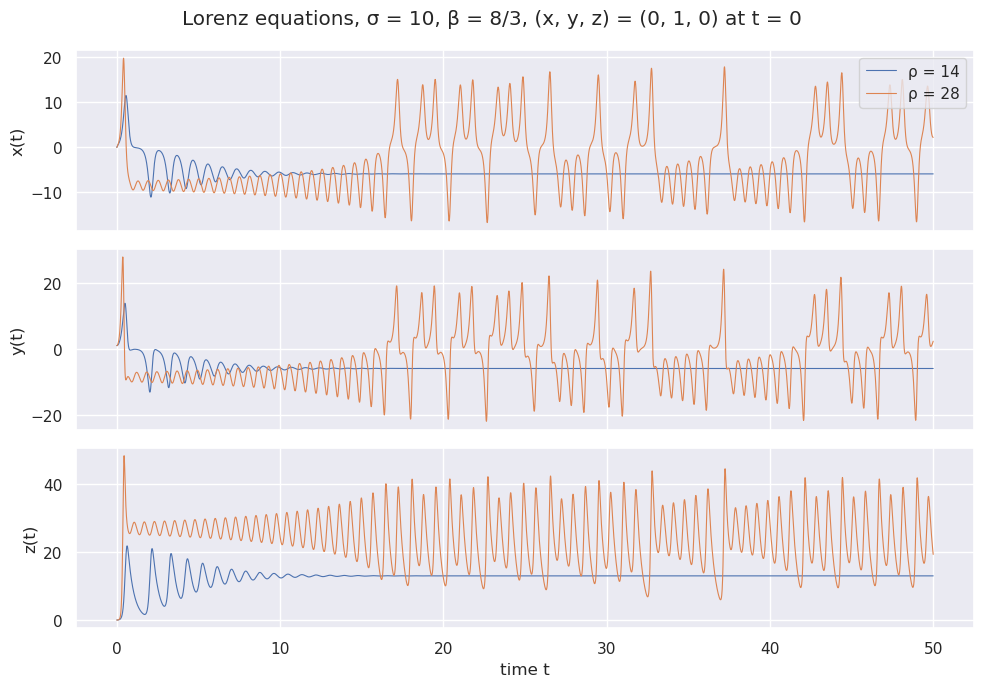

In [3]:
def lorenz(sigma, rho, beta):
    """Right-hand side of the Lorenz equations for the given constants."""
    def f(t, r):
        x, y, z = r
        return np.array([sigma*(y - x), rho*x - y - x*z, x*y - beta*z])
    return f


sigma, beta = 10, 8/3
t_end, n = 50, 10001                     # h = 0.005
r0 = [0, 1, 0]
rhos = (14, 28)                          # rho = 14 settles to a fixed point, rho = 28 is chaotic
sols = {rho: rk4(lorenz(sigma, rho, beta), 0, t_end, n, r0) for rho in rhos}

fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for rho, (t, r) in sols.items():
    for i, name in enumerate(('x', 'y', 'z')):
        axs[i].plot(t, r[:, i], lw=0.8, label=f'ρ = {rho}')
        axs[i].set_ylabel(f'{name}(t)')
axs[-1].set_xlabel('time t')
axs[0].legend(loc='upper right')
fig.suptitle('Lorenz equations, σ = 10, β = 8/3, (x, y, z) = (0, 1, 0) at t = 0')
fig.tight_layout()
plt.show()

In [4]:
# rho = 14: the trajectory ends on the stable fixed point (-c, -c, rho - 1) with c = sqrt(beta*(rho - 1))
r_end = sols[14][1][-1]
c14 = np.sqrt(beta*(14 - 1))
print(f'ρ = 14 ends at ({r_end[0]:.3f}, {r_end[1]:.3f}, {r_end[2]:.3f}), fixed point at ({-c14:.3f}, {-c14:.3f}, 13)')

# rho = 28: sensitivity to the initial condition and to the step size
t, r = sols[28]
_, r_shift = rk4(lorenz(sigma, 28, beta), 0, t_end, n, [0, 1 + 1e-8, 0])    # y(0) moved by 1e-8
_, r_half = rk4(lorenz(sigma, 28, beta), 0, t_end, 2*n - 1, r0)            # same start, h halved
gap_ic = np.linalg.norm(r - r_shift, axis=1)
gap_h = np.linalg.norm(r - r_half[::2], axis=1)
print(f'ρ = 28: runs starting 1e-8 apart differ by more than 1 from t = {t[np.argmax(gap_ic > 1)]:.1f}')
print(f'ρ = 28: runs with h and h/2 differ by more than 1 from t = {t[np.argmax(gap_h > 1)]:.1f}')

ρ = 14 ends at (-5.888, -5.888, 13.000), fixed point at (-5.888, -5.888, 13)
ρ = 28: runs starting 1e-8 apart differ by more than 1 from t = 32.5
ρ = 28: runs with h and h/2 differ by more than 1 from t = 29.3


**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

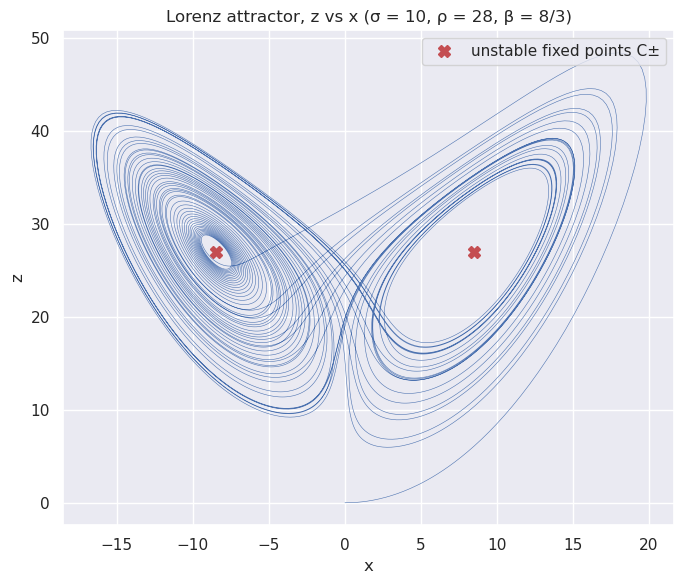

In [5]:
t, r = sols[28]
c28 = np.sqrt(beta*(28 - 1))               # unstable fixed points C± = (±c, ±c, rho - 1)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(r[:, 0], r[:, 2], lw=0.4, color='C0')
ax.plot([-c28, c28], [27, 27], 'X', color='C3', ms=9, label='unstable fixed points C±')
ax.set(xlabel='x', ylabel='z', title='Lorenz attractor, z vs x (σ = 10, ρ = 28, β = 8/3)')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig('lorenz_butterfly.png', dpi=150)
plt.show()

### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

**Approach.** Each second-order equation is rewritten as two first-order ones with s = (x, v), v = dx/dt, and solved with `rk4()`. Only the right-hand side changes between parts: `harmonic()`, `anharmonic()` and `van_der_pol()`. The period is measured with `period()` and compared with the exact value where one is known.

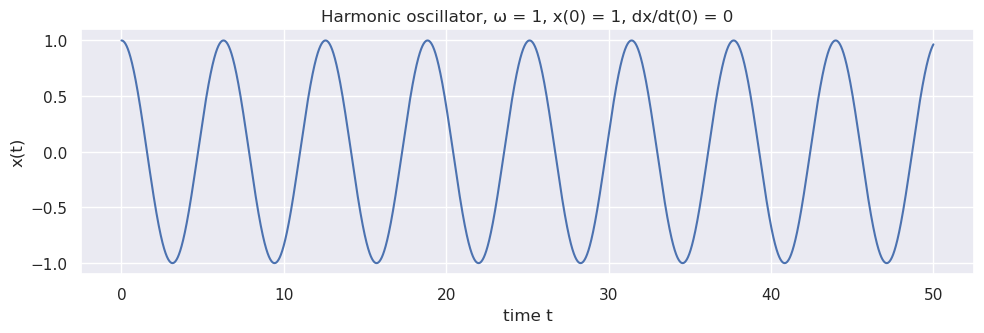

In [6]:
def harmonic(omega):
    """d²x/dt² = -ω² x as dx/dt = v, dv/dt = -ω² x, with s = (x, v)."""
    return lambda t, s: np.array([s[1], -omega**2*s[0]])


omega = 1
t_end, n = 50, 10001                       # h = 0.005
t, s = rk4(harmonic(omega), 0, t_end, n, [1, 0])

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, s[:, 0])
ax.set(xlabel='time t', ylabel='x(t)', title='Harmonic oscillator, ω = 1, x(0) = 1, dx/dt(0) = 0')
fig.tight_layout()
plt.show()

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

x(0) = 1: period = 6.2832   (2π/ω = 6.2832)
x(0) = 2: period = 6.2832   (2π/ω = 6.2832)


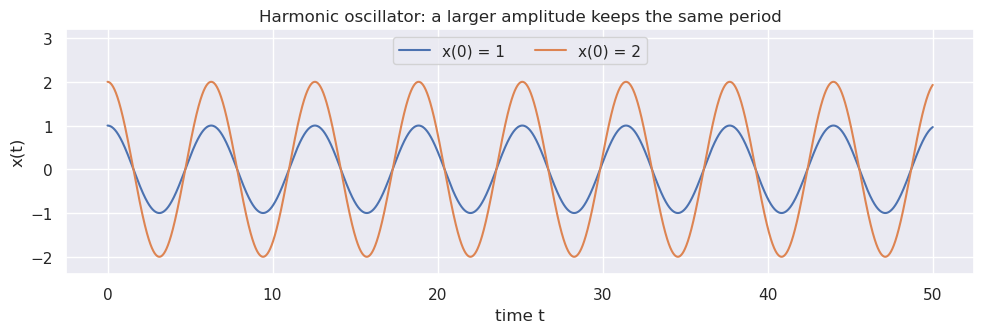

In [7]:
harm = {x0: rk4(harmonic(omega), 0, t_end, n, [x0, 0]) for x0 in (1, 2)}

fig, ax = plt.subplots(figsize=(10, 3.5))
for x0, (t, s) in harm.items():
    ax.plot(t, s[:, 0], label=f'x(0) = {x0}')
    print(f'x(0) = {x0}: period = {period(t, s[:, 0]):.4f}   (2π/ω = {2*np.pi/omega:.4f})')
ax.set(ylim=(-2.4, 3.2), xlabel='time t', ylabel='x(t)', title='Harmonic oscillator: a larger amplitude keeps the same period')
ax.legend(loc='upper center', ncol=2)       # headroom above the curves keeps the legend clear
fig.tight_layout()
plt.show()

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

x(0) = 0.5: period = 14.8326   (exact Γ(1/4)²/(√π ω x0) = 14.8326)
x(0) = 1: period = 7.4163   (exact Γ(1/4)²/(√π ω x0) = 7.4163)
x(0) = 2: period = 3.7081   (exact Γ(1/4)²/(√π ω x0) = 3.7081)


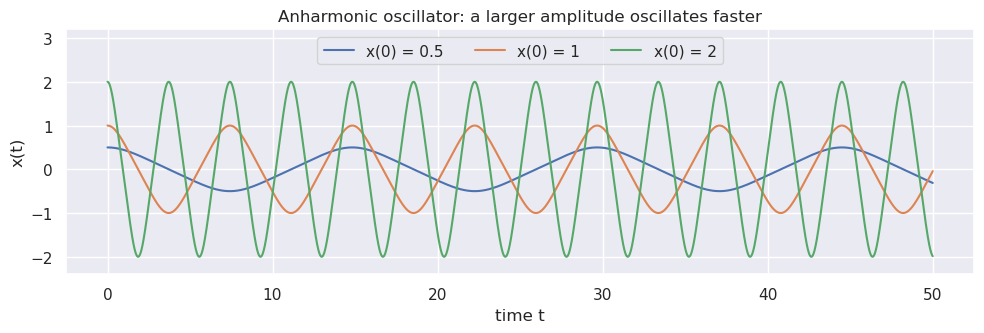

In [8]:
import math


def anharmonic(omega):
    """d²x/dt² = -ω² x³ as dx/dt = v, dv/dt = -ω² x³, with s = (x, v)."""
    return lambda t, s: np.array([s[1], -omega**2*s[0]**3])


anh = {x0: rk4(anharmonic(omega), 0, t_end, n, [x0, 0]) for x0 in (0.5, 1, 2)}

fig, ax = plt.subplots(figsize=(10, 3.5))
for x0, (t, s) in anh.items():
    ax.plot(t, s[:, 0], label=f'x(0) = {x0}')
    T_exact = math.gamma(0.25)**2/(np.sqrt(np.pi)*omega*x0)   # from energy conservation, T is proportional to 1/amplitude
    print(f'x(0) = {x0}: period = {period(t, s[:, 0]):.4f}   (exact Γ(1/4)²/(√π ω x0) = {T_exact:.4f})')
ax.set(ylim=(-2.4, 3.2), xlabel='time t', ylabel='x(t)', title='Anharmonic oscillator: a larger amplitude oscillates faster')
ax.legend(loc='upper center', ncol=3)
fig.tight_layout()
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

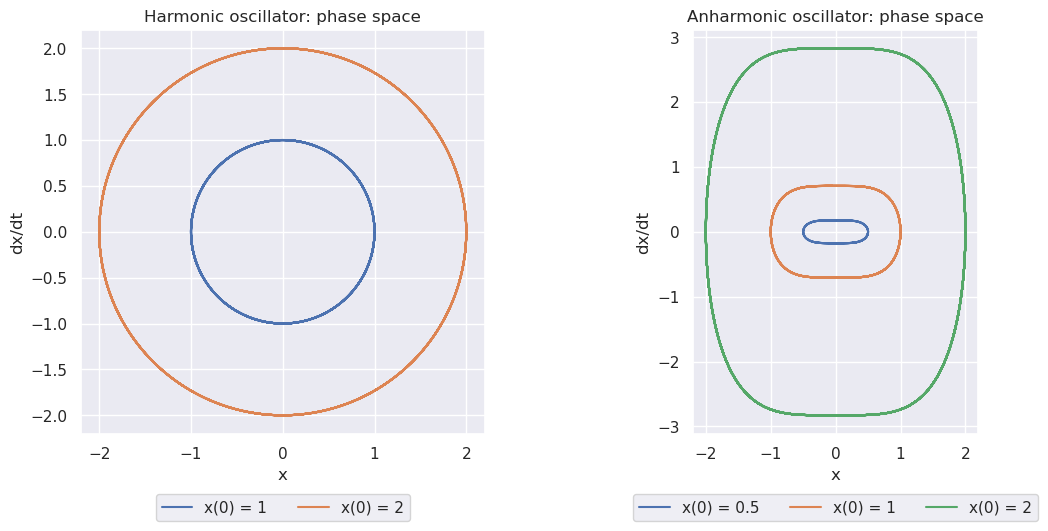

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
for x0, (t, s) in harm.items():
    axs[0].plot(s[:, 0], s[:, 1], label=f'x(0) = {x0}')
for x0, (t, s) in anh.items():
    axs[1].plot(s[:, 0], s[:, 1], label=f'x(0) = {x0}')
for ax, name in zip(axs, ('Harmonic', 'Anharmonic')):
    ax.set(xlabel='x', ylabel='dx/dt', title=f'{name} oscillator: phase space')
    ax.set_aspect('equal')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)   # below the axes, clear of the curves
fig.tight_layout()
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

μ = 1: period = 6.663, largest change when h is halved = 1.5e-10
μ = 2: period = 7.630, largest change when h is halved = 2.4e-09
μ = 4: period = 10.204, largest change when h is halved = 8.2e-08


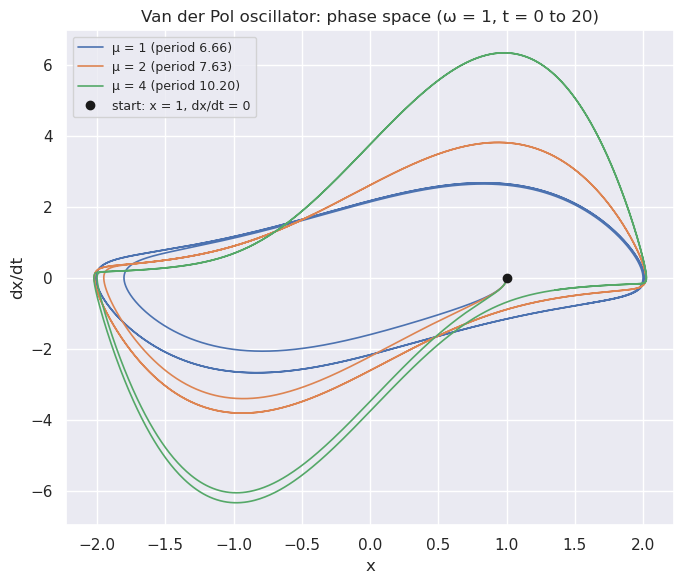

In [10]:
def van_der_pol(mu, omega=1):
    """d²x/dt² - μ(1 - x²) dx/dt + ω² x = 0 as dx/dt = v, dv/dt = μ(1 - x²) v - ω² x, with s = (x, v)."""
    return lambda t, s: np.array([s[1], mu*(1 - s[0]**2)*s[1] - omega**2*s[0]])


t_end, n = 20, 10001                       # h = 0.002

fig, ax = plt.subplots(figsize=(7, 6))
for mu in (1, 2, 4):
    t, s = rk4(van_der_pol(mu), 0, t_end, n, [1, 0])
    _, s_half = rk4(van_der_pol(mu), 0, t_end, 2*n - 1, [1, 0])       # accuracy check with h halved
    T_mu = period(t, s[:, 0])
    ax.plot(s[:, 0], s[:, 1], lw=1.2, label=f'μ = {mu} (period {T_mu:.2f})')
    print(f'μ = {mu}: period = {T_mu:.3f}, largest change when h is halved = {np.abs(s_half[::2] - s).max():.1e}')
ax.plot(1, 0, 'ko', ms=6, label='start: x = 1, dx/dt = 0')
ax.set(xlabel='x', ylabel='dx/dt', title='Van der Pol oscillator: phase space (ω = 1, t = 0 to 20)')
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout()
fig.savefig('vdp_phase.png', dpi=150)
plt.show()

### Euler vs RK4
A check on the harmonic oscillator, whose exact solution x(t) = cos t is known, used in the report discussion. "Euler at h/4" takes four times as many steps, so it makes the same number of calls to f as RK4 at h.

In [11]:
print('Harmonic oscillator, ω = 1, t = 0 to 50, exact solution x(t) = cos t')
print(f'{"h":>7} {"Euler max error":>16} {"RK4 max error":>14} {"Euler at h/4 (same cost)":>25} {"Euler E(50)/E(0)":>17}')
for h in (0.05, 0.005):
    n_h = int(round(50/h)) + 1
    t, se = euler(harmonic(1), 0, 50, n_h, [1, 0])
    _, sr = rk4(harmonic(1), 0, 50, n_h, [1, 0])
    t4, se4 = euler(harmonic(1), 0, 50, 4*(n_h - 1) + 1, [1, 0])     # 4 times the steps: same number of f calls as RK4
    energy_ratio = se[-1, 0]**2 + se[-1, 1]**2                       # E = (x² + v²)/2 and E(0) = 1/2
    print(f'{h:7.3f} {np.abs(se[:, 0] - np.cos(t)).max():16.2e} {np.abs(sr[:, 0] - np.cos(t)).max():14.2e} '
          f'{np.abs(se4[:, 0] - np.cos(t4)).max():25.2e} {energy_ratio:17.3f}')

Harmonic oscillator, ω = 1, t = 0 to 50, exact solution x(t) = cos t
      h  Euler max error  RK4 max error  Euler at h/4 (same cost)  Euler E(50)/E(0)
  0.050         2.36e+00       2.54e-06                  3.53e-01            12.145
  0.005         1.28e-01       2.54e-10                  3.06e-02             1.284


#### Problem code summary

The script solves the Lorenz equations and the harmonic, anharmonic and van der Pol oscillators with one RK4 solver, by writing every problem as a first-order system dy/dt = f(t, y). Each problem only supplies its right-hand side through a small function such as `lorenz()` or `van_der_pol()`, so the solver, the period measurement and the plots are reused without change. RK4 was chosen over Euler because the Euler vs RK4 check shows that, for the same number of evaluations of f, its error is about 10^8 times smaller.

---
## Section 3: Notes

In [ ]:
import numpy as np

# Ricatti equation (mildly nonlinear)
def f(x,y):
    return - (30/(1-x**2)) + ((2*x)/(1-x**2))*y - y**2

### IVPs

#### 1st order ODE solver: Euler's method

In [ ]:
# forward Euler's method
def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

#### 1st order ODE solver: Rungke-Kutta method

In [ ]:
# 4th order Runge-Kutta method
def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

In [5]:
# execution
a, b, n, yinit = 0.05, 0.49, 12, 19.53
xs, ys = euler(f,a,b,n,yinit); print(ys)
xs, ys = rk4(f,a,b,n,yinit); print(ys)

[ 19.53         3.14847227   1.56501191   0.26296871  -0.97182666
  -2.28204589  -3.81903888  -5.80936521  -8.6780744  -13.37838499
 -22.50759395 -45.29198435]
[ 19.53        10.16782416   6.37032643   4.11921483   2.48829431
   1.12081032  -0.17770512  -1.56533384  -3.24322678  -5.58940124
  -9.6041146  -19.50349262]


#### 2nd-order ODE: RK4

In [12]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])
    
def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[ 0.09265871  1.80962109]
 [ 0.16241651  1.66496084]
 [ 0.22481633  1.44262901]
 [ 0.27687631  1.1492782 ]
 [ 0.3159291   0.79398005]
 [ 0.33971857  0.38822519]
 [ 0.34649662 -0.05407672]
 [ 0.33511993 -0.51659705]
 [ 0.3051467  -0.98058819]
 [ 0.25693343 -1.42488364]
 [ 0.19173167 -1.82589807]
 [ 0.1117848  -2.15762739]]


In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Updated to handle arrays (systems of ODEs)
def euler(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

def rk4(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

#### Shooting methods

In [11]:
def secant(f,x0,x1,kmax=200,tol=1.e-8):
    f0 = f(x0)
    for k in range(1,kmax):
        f1 = f(x1)
        ratio = (x1 - x0)/(f1 - f0)
        x2 = x1 - f1*ratio
        xdiff = abs(x2-x1)
        x0, x1 = x1, x2
        f0 = f1
        rowf = "{0:2d}{1:1.16f} {2:1.16f} {3:1.16f}"
        print(rowf.format(k,x2,xdiff,abs(f(x2))))
        if abs(xdiff/x2) < tol:
            break
    else:
        x2 = None
    
    return x2

def shoot(sig):
    a, b, n = 0.05, 0.49, 100
    yinits = np.array([0.0926587109375, sig])
    xs, ys = rk4gen(fs,a,b,n,yinits)
    wfinal = 0.11177050858750004
    return ys[-1, 0] - wfinal

wder = secant(shoot,0.,1.)
print(wder)

 11.8096210699240751 0.8096210699240751 0.0000000000000001
 21.8096210699240738 0.0000000000000013 0.0000000000000001
1.8096210699240738


#### BVP matrix

In [8]:
from gauelimpivot import gauelimpivot
import numpy as np

def matsetup(a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    A = np.zeros((n,n))
    np.filldiagonal(A, -2 + 30*h**2/(1-xs**2))
    A[0,0] = 1; A[-1,-1] = 1
    np.filldiagonal(A[1:,:], 1 + h*xs[1:]/(1-xs[1:]**2))
    A[-1,-2] = 0
    np.filldiagonal(A[:,1:], 1 - h*xs/(1-xs**2))
    A[0,1] = 0
    bs = np.zeros(n)
    bs[0] = 0.0926587109375
    bs[-1] = 0.11177050858750004
    return A, bs

def riccati(a,b,n):
    A, bs = matsetup(a, b, n)
    ws = gauelimpivot(A, bs)
    return ws

a, b, n = 0.05, 0.49, 400
ws = riccati(a, b, n); print(ws)

ModuleNotFoundError: No module named 'gauelimpivot'

#### Shooting method

In [9]:
from secant import secant
import numpy as np

def fs(x,yvals,s):
    q = 1.5
    y0, y1 = yvals
    f0 = y1
    f1 = (2*q*np.cos(2*x) - s)*y0
    return np.array([f0, f1])

def rk4geneig(fs,a,b,n,yinits,s):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals,s)
        k1 = h*fs(x+h/2, yvals+k0/2,s)
        k2 = h*fs(x+h/2, yvals+k1/2,s)
        k3 = h*fs(x+h, yvals+k2,s)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys
    
def shoot(s):
    a, b, n = 0, 2*np.pi, 500
    yinits = np.array([0., 5.])
    xs, ys = rk4geneig(fs,a,b,n,yinits,s)
    wfinal = 0.
    return ys[-1, 0] - wfinal

for sinit in (-0.4, 3.3, 8.5):
    sval = secant(shoot,sinit,sinit+0.5)
    print(sval, end=" ")

ModuleNotFoundError: No module named 'secant'

#### Matrix approach

In [10]:
from qrmet import qrmet
import numpy as np

def matsetup(q,n):
    h = 2*np.pi/n
    xs = np.arange(n)*h
    A = np.zeros((n,n))
    np.filldiagonal(A, -2 - 2*h**2*q*np.cos(2*xs))
    np.filldiagonal(A[1:,:], 1)
    np.filldiagonal(A[:,1:], 1)
    A[0,-1] = 1
    A[-1,0] = 1
    return A

def mathieu(q,n):
    A = matsetup(q, n)
    qreigvals = qrmet(A,200)
    h = 2*np.pi/n
    qreigvals = np.sort(-qreigvals/h**2)
    return qreigvals

q, n = 1.5, 200
qreigvals = mathieu(q, n)
print(qreigvals[:6])

ModuleNotFoundError: No module named 'qrmet'

### Plotting

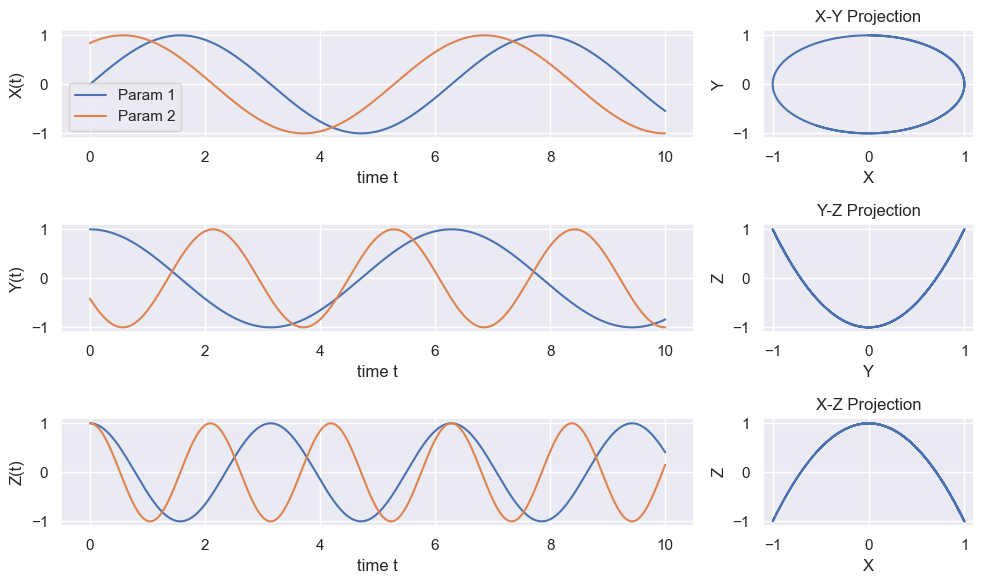

In [2]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)


# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{dy_0}{dt} &= y_1 \\
\frac{dy_1}{dt} &= -\frac{g}{l}\sin(y_0)
\end{align}

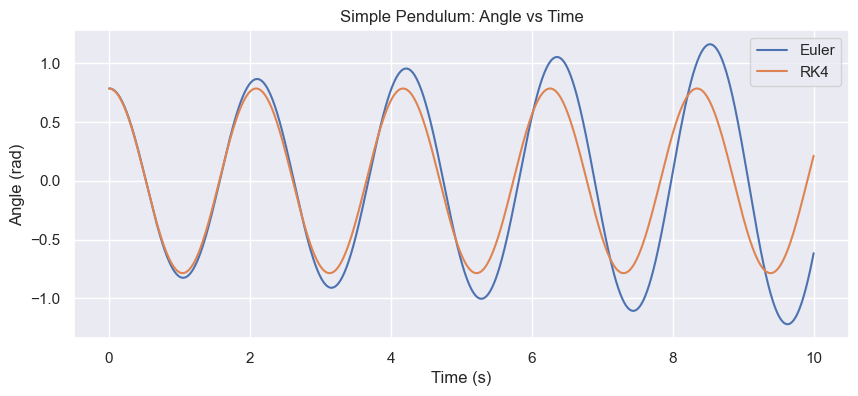

In [15]:
def pendulum_ode(t, Y):
    g = 9.81
    l = 1.0
    theta, omega = Y
    return np.array([omega, -(g/l)*np.sin(theta)])

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = [np.pi/4, 0.0]
t, Y_euler = euler(pendulum_ode, 0, 10, 1000, yinit)
t, Y_rk4 = rk4(pendulum_ode, 0, 10, 1000, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title("Simple Pendulum: Angle vs Time")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()